# Imports

In [1]:
%cd ..

/Users/emir.demic/Desktop/PhD/Research/Irena 2025/moral-reasoning-2026a


In [2]:
import os
from pprint import pprint

import pandas as pd
import numpy as np
import pingouin as pn
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
import scipy.stats as stats

from src.util import value_labels
from src.models.regression import bootstrap_regression
from src.descriptives import descriptive_stat, scale_stat
from src.charts.assumptions import plot_qq_residuals

In [3]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

In [4]:
short_df = pd.read_csv("data/processed/01_short_form_data.csv")
long_df = pd.read_csv("data/processed/01_long_form_data.csv")

# Data Prep

In [5]:
short_df.head()

,Participant_ID,age,gender,education,residence,ses,MFQ2_C_1,MFQ2_C_2,MFQ2_C_3,MFQ2_C_4,...,MFQ_A,MFQ_P,CRT1_correct,CRT2_correct,CRT3_correct,CRT4_correct,CRT5_correct,CRT6_correct,CRT7_correct,CRT8_correct
0,727,38.0,1,4,3,3,5,4,5,5,...,4.000000,4.000000,0,0,1,1,0,0,0,1
1,88,30.0,1,4,4,2,3,2,3,2,...,3.166667,3.166667,0,0,0,1,0,0,0,0
2,544,51.0,1,6,1,4,5,5,3,5,...,4.500000,4.166667,0,0,0,1,0,0,0,1
3,115,50.0,1,3,1,1,5,5,5,5,...,2.666667,4.000000,1,0,0,1,0,0,0,0
4,396,40.0,1,4,4,3,5,1,5,5,...,3.666667,3.000000,0,0,0,0,0,0,0,0


In [6]:
norm_columns = ["MFQ_C", "MFQ_E", "MFQ_PRO", "MFQ_L", "MFQ_A", "MFQ_P"]

short_df["primary_norm"] = short_df[norm_columns].max(axis=1)
short_df["primary_norm_name"] = short_df[["MFQ_C", "MFQ_E", "MFQ_PRO", "MFQ_L", "MFQ_A", "MFQ_P"]].idxmax(axis=1)

short_df["max_count"] = (short_df[norm_columns] == short_df["primary_norm"].values[:, None]).sum(axis=1)

short_df = short_df[short_df["max_count"] == 1].copy()
short_df = short_df.drop("max_count", axis=1)

for index, primary_norm in short_df["primary_norm_name"].items():
    short_df.loc[index, "primary_norm_cont"] = short_df.loc[index, primary_norm]

In [7]:
short_df.shape

(632, 106)

# Correlations

The next cell calculates Pearson's correlation between each of the thinking style measures and CRT measures and the value of the participants' primary norm.

In [8]:
correlation_results = {}
for i in ["AOT", "CM", "PIT", "PE", "CRT_Correct", "CRT_Heuristic"]:
    corr = pn.corr(short_df["primary_norm_cont"], short_df[i])
    correlation_results[i] = {
        "r": round(corr.at["pearson", "r"], 2),
        "CI95%": corr.at["pearson", "CI95%"],
        "p-val": round(corr.at["pearson", "p-val"], 4),
    }

In [9]:
pd.DataFrame(correlation_results).T

,r,CI95%,p-val
AOT,-0.02,"[-0.1, 0.06]",0.566
CM,0.13,"[0.05, 0.2]",0.0013
PIT,0.15,"[0.07, 0.22]",0.0002
PE,-0.01,"[-0.09, 0.06]",0.7163
CRT_Correct,-0.05,"[-0.13, 0.03]",0.2147
CRT_Heuristic,0.02,"[-0.06, 0.1]",0.5839


# Regression Analysis

### Full Regression Model

In [10]:
ind_variables = [
    "AOT",
    "CM",
    "PIT",
    "PE",
    "CRT_Correct",
    "CRT_Heuristic",
]

for i in range(len(ind_variables)):
    var_name = ind_variables[i]
    print(f"VIF factor for {var_name}: {round(variance_inflation_factor(short_df[ind_variables], i), 2)}.")

VIF factor for AOT: 21.09.
VIF factor for CM: 7.73.
VIF factor for PIT: 10.59.
VIF factor for PE: 30.36.
VIF factor for CRT_Correct: 9.15.
VIF factor for CRT_Heuristic: 6.31.


VIF values indicate problems with multicollinearity. The first regression model will be run with the full model specification (i.e. all independent variables), while the subsequent one will be run only on the subset that leads to VIF <= 10.

In [11]:
full_X = short_df[ind_variables]
full_X = sm.add_constant(full_X)
full_model = sm.OLS(short_df["primary_norm_cont"], full_X, hasconst=True).fit()
full_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      primary_norm_cont   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     3.946
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           0.000698
Time:                        18:14:27   Log-Likelihood:                -399.95
No. Observations:                 632   AIC:                             813.9
Df Residuals:                     625   BIC:                             845.0
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.9655      0.199     19.964      0.000       3.575       4.356
AOT               0.0297      0.018      1.612      0.107      -0.006       0.066
CM                0.0416      0.016      2.656      0.008       0.011       0.072
PIT               0.0529      0.016      3.374      0.001       0.022       0.084
PE                0.0151      0.022      0.697      0.486      -0.028       0.058
CRT_Correct      -0.0148      0.013     -1.151      0.250      -0.040       0.010
CRT_Heuristic    -0.0151      0.015     -0.978      0.328      -0.045       0.015
==============================================================================
Omnibus:                       87.328   Durbin-Watson:                   1.947
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              126.016
Skew:                          -0.960   Prob(JB):                     4.32e-28
Kurtosis:                       4.049   Cond. No.                         114.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [12]:
std_params = [
    round(p * short_df[i].std() / short_df["primary_norm_cont"].std(), 2)
    for i, p in full_model.params.items()
    if i != "const"
]
std_params.insert(0, None)

full_model_coeff = pd.DataFrame(
    data={
        "vars": full_model.params.index.values.tolist(),
        "params": round(full_model.params, 2),
        "se": round(full_model.bse, 2),
        "std_params": std_params,
        "95% CI-L": round(full_model.conf_int()[0], 2),
        "95% CI-U": round(full_model.conf_int()[1], 2),
        "ttest": round(full_model.tvalues, 3),
        "p_value": round(full_model.pvalues, 4),
    }
)
full_model_coeff.to_csv("results/coefficients/03_regression_primary_norm.csv", index=False)

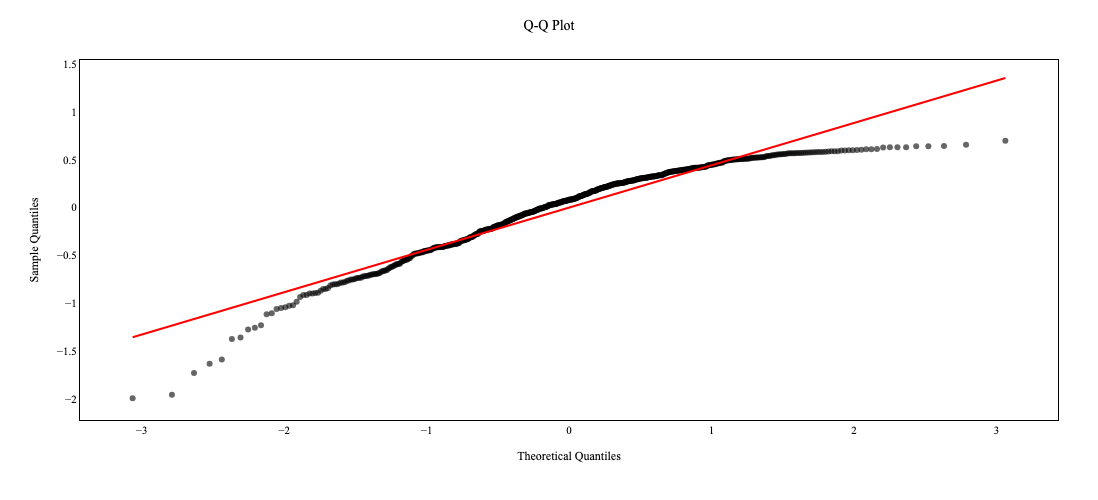

In [13]:
full_qq_plot = plot_qq_residuals(full_model.resid)
full_qq_plot.write_image("results/figures/01_Q-Q_Plot_Full_Model_Primary_Norm.png", width=600, height=500, scale=3)
full_qq_plot.show()

In [14]:
full_model_bp_test = het_breuschpagan(full_model.resid, full_model.model.exog)
labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
pprint({labels[i]: round(full_model_bp_test[i], 3) for i in range(len(labels))})

{'F-Statistic': np.float64(2.255),
 'F-Test p-value': np.float64(0.037),
 'LM Statistic': np.float64(13.394),
 'LM-Test p-value': np.float64(0.037)}


In [15]:
full_model_robust = full_model.get_robustcov_results(cov_type='HC3')
# No significant differences between a model with robust estimates of standard errors and the one above
full_model_robust.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      primary_norm_cont   R-squared:                       0.037
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     4.265
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           0.000319
Time:                        18:14:29   Log-Likelihood:                -399.95
No. Observations:                 632   AIC:                             813.9
Df Residuals:                     625   BIC:                             845.0
Df Model:                           6                                         
Covariance Type:                  HC3                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
const             3.9655      0.195     20.363      0.000       3.583       4.348
AOT               0.0297      0.017      1.765      0.078      -0.003       0.063
CM                0.0416      0.015      2.849      0.005       0.013       0.070
PIT               0.0529      0.015      3.545      0.000       0.024       0.082
PE                0.0151      0.021      0.720      0.472      -0.026       0.056
CRT_Correct      -0.0148      0.012     -1.245      0.213      -0.038       0.009
CRT_Heuristic    -0.0151      0.014     -1.066      0.287      -0.043       0.013
==============================================================================
Omnibus:                       87.328   Durbin-Watson:                   1.947
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              126.016
Skew:                          -0.960   Prob(JB):                     4.32e-28
Kurtosis:                       4.049   Cond. No.                         114.
==============================================================================

Notes:
[1] Standard Errors are heteroscedasticity robust (HC3)
"""

In [16]:
bootstrap_regression(full_model, full_X, short_df["primary_norm_cont"])

,original_coef,boot_mean,boot_se,ci_lower,ci_upper
const,3.9655,3.9615,0.1934,3.5827,4.3412
AOT,0.0297,0.0298,0.0166,-0.0027,0.0629
CM,0.0416,0.0416,0.0144,0.0134,0.0696
PIT,0.0529,0.0530,0.0148,0.0246,0.0823
PE,0.0151,0.0154,0.0208,-0.0257,0.0563
CRT_Correct,-0.0148,-0.0146,0.0118,-0.0370,0.0090
CRT_Heuristic,-0.0151,-0.0150,0.0139,-0.0422,0.0122


### Partial Model

In [17]:
# By removing CRT_Heuristic and PE variables, the VIF falls below the 10-threshold
partial_ind_variables = [
    "AOT",
    "CM",
    "PIT",
    "CRT_Correct",
]

for i in range(len(partial_ind_variables)):
    var_name = partial_ind_variables[i]
    print(f"VIF factor for {var_name}: {round(variance_inflation_factor(short_df[partial_ind_variables], i), 2)}.")

VIF factor for AOT: 8.68.
VIF factor for CM: 7.51.
VIF factor for PIT: 7.78.
VIF factor for CRT_Correct: 3.65.


In [18]:
partial_X = short_df[partial_ind_variables]
partial_X = sm.add_constant(partial_X)
partial_model = sm.OLS(short_df["primary_norm_cont"], partial_X, hasconst=True).fit()
partial_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:      primary_norm_cont   R-squared:                       0.034
Model:                            OLS   Adj. R-squared:                  0.028
Method:                 Least Squares   F-statistic:                     5.573
Date:                Wed, 21 Jan 2026   Prob (F-statistic):           0.000206
Time:                        18:14:32   Log-Likelihood:                -400.66
No. Observations:                 632   AIC:                             811.3
Df Residuals:                     627   BIC:                             833.6
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           3.9877      0.145     27.413      0.000       3.702       4.273
AOT             0.0298      0.018      1.638      0.102      -0.006       0.066
CM              0.0392      0.015      2.574      0.010       0.009       0.069
PIT             0.0517      0.016      3.311      0.001       0.021       0.082
CRT_Correct    -0.0043      0.008     -0.543      0.587      -0.020       0.011
==============================================================================
Omnibus:                       84.783   Durbin-Watson:                   1.939
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              120.179
Skew:                          -0.949   Prob(JB):                     8.01e-27
Kurtosis:                       3.980   Cond. No.                         67.8
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

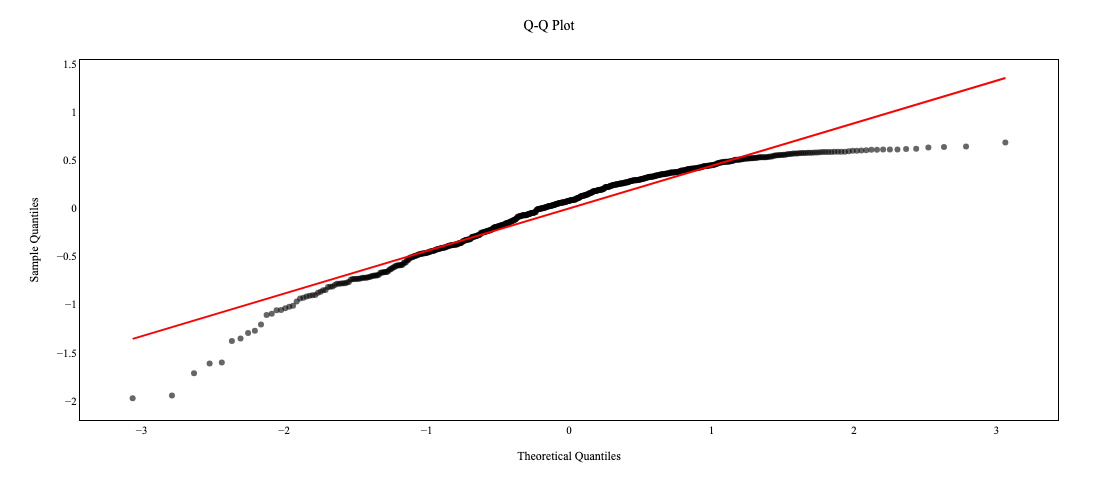

In [19]:
partial_qq_plot = plot_qq_residuals(partial_model.resid)
partial_qq_plot.write_image("results/figures/02_Q-Q_Plot_Partial_Model_Primary_Norm.png", width=600, height=500, scale=3)
partial_qq_plot.show()

In [20]:
partial_model_bp_test = het_breuschpagan(partial_model.resid, partial_model.model.exog)
labels = ['LM Statistic', 'LM-Test p-value', 'F-Statistic', 'F-Test p-value']
pprint({labels[i]: round(partial_model_bp_test[i], 3) for i in range(len(labels))})

{'F-Statistic': np.float64(1.438),
 'F-Test p-value': np.float64(0.22),
 'LM Statistic': np.float64(5.745),
 'LM-Test p-value': np.float64(0.219)}


In [21]:
bootstrap_regression(partial_model, partial_X, short_df["primary_norm_cont"])

,original_coef,boot_mean,boot_se,ci_lower,ci_upper
const,3.9877,3.9864,0.1367,3.7152,4.2543
AOT,0.0298,0.0299,0.0167,-0.0027,0.0626
CM,0.0392,0.0392,0.0141,0.0119,0.0663
PIT,0.0517,0.0518,0.0149,0.0233,0.0813
CRT_Correct,-0.0043,-0.0041,0.0077,-0.0190,0.0112
